---
tags: [algorithm, optimization, variational]
---

# Pauli Correlation Encoding

In this tutorial we solve the MaxCut problem with Pauli Correlation
Encoding (PCE) using Qamomile's `PauliCorrelationEncoding`. PCE maps $N$ spin
variables to expectation values of $k$-body Pauli correlators on a
register of $n = \mathcal{O}(N^{1/k})$ qubits. This reduces the qubit
count compared with a one-qubit-per-variable QAOA formulation.

We solve a 20-vertex MaxCut instance on **3 qubits** with $k = 2$.
The workflow builds the encoding with `PauliCorrelationEncoding`, estimates each
correlator expectation value with a hardware-efficient `@qkernel`
ansatz, optimizes the ansatz with `scipy.optimize.minimize`, decodes
the final expectations with `encoding.decode`, and compares the
result with a brute-force baseline.

## Installation

```bash
pip install "qamomile[qiskit,visualization]"
```

In [1]:
# Install the latest Qamomile through pip!
# !pip install "qamomile[qiskit,visualization]"

In [2]:
import itertools
import os

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from scipy.optimize import minimize

import qamomile as qm
from qamomile.measurement import Estimator
from qamomile.optimization import BinaryModel, PauliCorrelationEncoding
from qamomile.qiskit import Aer, to_circuit

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"

(problem-settings)=
## Problem Settings: MaxCut

### Problem Definition

Given an undirected graph $G = (V, E)$, the MaxCut problem asks for
a partition of the vertices into two sets $S$ and $\bar{S}$ so that the
number of edges between the two sets is maximized. We assign each
vertex a spin variable $s_i \in \{+1, -1\}$. The value
$s_i = +1$ places vertex $i$ in $S$, and $s_i = -1$ places it in
$\bar{S}$. The cut value is

$$
\text{MaxCut}(\mathbf{s})
\;=\; \frac{1}{2} \sum_{(i,j) \in E} \bigl(\,1 - s_i s_j\,\bigr).
$$

Each edge contributes $1$ when its endpoints sit on opposite sides
($s_i s_j = -1$) and $0$ when they sit on the same side
($s_i s_j = +1$). Maximizing the cut is therefore equivalent to
**minimizing** the Ising energy

$$
E(\mathbf{s}) \;=\; \frac{1}{2} \sum_{(i,j) \in E} s_i s_j
    \;-\; \frac{|E|}{2}, \qquad E(\mathbf{s}) = -\,\text{MaxCut}(\mathbf{s}),
$$

This is an Ising model with $h_i = 0$, $J_{ij} = \tfrac{1}{2}$ on
every edge, and a constant offset $-|E|/2$. PCE works directly with
this spin form, so we do not need an extra conversion from binary
variables $x \in \{0, 1\}$.

### Create the Graph

We use a 20-node 3-regular random graph (every vertex has exactly
three neighbors, giving $|E| = 3 \cdot 20 / 2 = 30$ edges). MaxCut on
a 3-regular graph is a benchmark in the PCE paper. The instance is
also small enough for the brute-force baseline to compute the true
optimum.

`nx.random_regular_graph` can produce disconnected graphs, so we
increase the seed until the graph is connected. This keeps the
example to one partitioning problem instead of several independent
components.

In [3]:
seed = 42
while True:
    graph = nx.random_regular_graph(3, 20, seed=seed)
    if nx.is_connected(graph):
        break
    seed += 1

NUM_NODES = graph.number_of_nodes()
NUM_EDGES = graph.number_of_edges()
EDGES = tuple(sorted(tuple(sorted(edge)) for edge in graph.edges()))
positions = nx.spring_layout(graph, seed=42)

print(f"Using graph seed {seed}: {NUM_NODES} nodes, {NUM_EDGES} edges")
assert NUM_NODES == 20
assert NUM_EDGES == 30

Using graph seed 42: 20 nodes, 30 edges


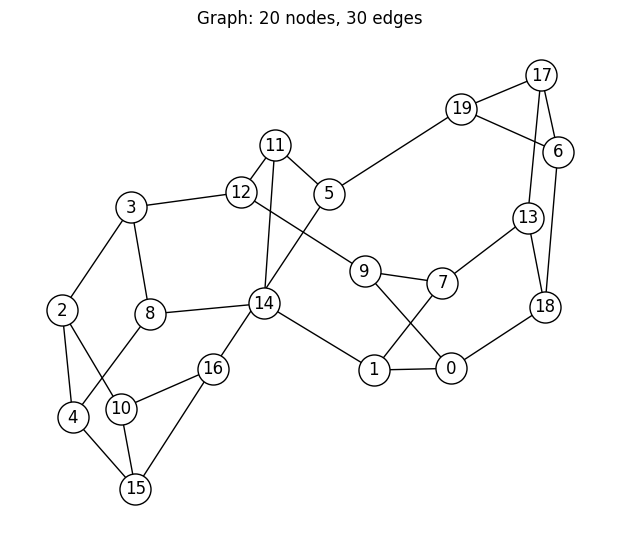

In [4]:
plt.figure(figsize=(6, 5))
nx.draw(
    graph,
    positions,
    with_labels=True,
    node_color="white",
    node_size=500,
    edgecolors="black",
)
plt.title(f"Graph: {NUM_NODES} nodes, {NUM_EDGES} edges")
plt.show()

(pce-algorithm)=
## Algorithm

PCE was introduced by Sciorilli et al.
{cite:p}`10.48550/arXiv.2401.09421` for combinatorial optimization
under tight qubit budgets. Standard QAOA uses one qubit
per variable. PCE uses $n = \mathcal{O}(N^{1/k})$ qubits for an
$N$-variable problem.

### PCE Encoding

PCE picks a correlator order $k > 1$ and assigns each spin
variable $i \in \{1, \dots, N\}$ to a distinct $k$-body Pauli
correlator $P_i$. Each $P_i$ is a tensor product of $k$ non-identity
Paulis from $\{X, Y, Z\}$ acting on $k$ of the $n$ qubits. The number
of distinct such correlators on $n$ qubits is
$\binom{n}{k} \cdot 3^k$, so $n$ is chosen as the smallest integer with

$$
\binom{n}{k} \cdot 3^k \;\ge\; N.
$$

At $k = 2$ this gives $n = \mathcal{O}(\sqrt{N})$; at $k = 3$ it gives
$n = \mathcal{O}(N^{1/3})$. For this $N = 20$ instance, $k = 2$
requires $n = 3$ qubits. This is the smallest integer with
$\binom{3}{2} \cdot 9 = 27 \ge 20$. The mapping from variables to
correlators is deterministic: pick any fixed enumeration of $k$-body
Pauli strings on $n$ qubits and assign the first $N$ of them to
variables $0, \dots, N-1$.

In [5]:
model = BinaryModel.from_ising(
    {edge: 0.5 for edge in EDGES},
    constant=-NUM_EDGES / 2.0,
    variables=range(NUM_NODES),
)
encoding = PauliCorrelationEncoding(model, correlator_order=2)

assert model.num_variables == NUM_NODES
assert encoding.num_qubits == 3
assert len(encoding.observables) == NUM_NODES
assert tuple(encoding.correlations) == model.variables
assert all(
    len(observable.terms) == 1
    and len(observable.terms[0][0].factors) == 2
    and observable.terms[0][1] == 1.0
    for observable in encoding.observables
)

print(f"Classical variables: {model.num_variables}")
print(f"PCE qubits: {encoding.num_qubits}")
print(f"Compression ratio: {model.num_variables / encoding.num_qubits:.1f}x")
for variable, observable in encoding.correlations.items():
    print(f"P_{variable:2d}: {observable}")

Classical variables: 20
PCE qubits: 3
Compression ratio: 6.7x
P_ 0: Hamiltonian(terms=((PauliWord(factors=(PauliFactor(index=0, pauli=<Pauli.X: 'X'>), PauliFactor(index=1, pauli=<Pauli.X: 'X'>))), (1+0j)),), constant=0j, num_qubits=3)
P_ 1: Hamiltonian(terms=((PauliWord(factors=(PauliFactor(index=0, pauli=<Pauli.X: 'X'>), PauliFactor(index=1, pauli=<Pauli.Y: 'Y'>))), (1+0j)),), constant=0j, num_qubits=3)
P_ 2: Hamiltonian(terms=((PauliWord(factors=(PauliFactor(index=0, pauli=<Pauli.X: 'X'>), PauliFactor(index=1, pauli=<Pauli.Z: 'Z'>))), (1+0j)),), constant=0j, num_qubits=3)
P_ 3: Hamiltonian(terms=((PauliWord(factors=(PauliFactor(index=0, pauli=<Pauli.Y: 'Y'>), PauliFactor(index=1, pauli=<Pauli.X: 'X'>))), (1+0j)),), constant=0j, num_qubits=3)
P_ 4: Hamiltonian(terms=((PauliWord(factors=(PauliFactor(index=0, pauli=<Pauli.Y: 'Y'>), PauliFactor(index=1, pauli=<Pauli.Y: 'Y'>))), (1+0j)),), constant=0j, num_qubits=3)
P_ 5: Hamiltonian(terms=((PauliWord(factors=(PauliFactor(index=0, pauli=<

### Cost Function

Given a parameterized ansatz state $|\Psi(\boldsymbol{\theta})\rangle$,
PCE turns the discrete spin objective

$$
C(\mathbf{s}) \;=\; \sum_i h_i \, s_i \,+\, \sum_{i<j} J_{ij} \, s_i s_j
$$

into a smooth surrogate loss function $\mathcal{L}$ by replacing each
spin $s_i$ with the tanh-relaxed correlator expectation
$\sigma_i(\boldsymbol{\theta}) = \tanh\bigl(\alpha\, \langle P_i \rangle\bigr)$,
and adding a quartic regularizer that discourages early
saturation of the relaxed variables. The tanh map keeps $\sigma_i$
inside the open interval $(-1, +1)$, where sign rounding can still
recover candidate bitstrings:

$$
\mathcal{L}(\boldsymbol{\theta})
\;=\; \underbrace{\sum_i h_i \, \sigma_i \,+\, \sum_{i<j} J_{ij} \, \sigma_i \sigma_j}_{\mathcal{L}_{\text{data}}}
      \,+\, \mathcal{L}_{\text{reg}}, \qquad
\mathcal{L}_{\text{reg}}
\;=\; \beta \cdot \nu \cdot \!\left[ \frac{1}{N} \sum_i \sigma_i^2 \right]^{\!2}.
$$

The data term pulls $\sigma_i$ and $\sigma_j$ toward opposite signs
for every connected pair (so $J_{ij} \sigma_i \sigma_j$ is negative);
the regularizer counterbalances this pressure by penalizing large
relaxed values. This keeps the optimizer in the smooth interior of the
domain and reduces early convergence to a suboptimal bitstring.

The loss carries three hyperparameters: $\alpha$ (tanh sharpness),
$\beta$ (regularizer strength), and $\nu$ (overall scale). Their
values affect optimizer convergence and final solution quality. The
concrete values used in this tutorial follow the original paper and
are configured in [](#pce-optimize-variational-parameters).

For MaxCut specifically, the spin model has $h_i = 0$ and
$J_{ij} = +\tfrac{1}{2}$ on every edge, so the data term is minimized
precisely when adjacent $\sigma_i, \sigma_j$ disagree in sign.

### Decoding

After convergence, PCE turns each optimized correlator expectation
value back into a discrete spin with sign rounding:

$$
s_i \;=\; \operatorname{sgn}\!\bigl\langle P_i \bigr\rangle_{\boldsymbol{\theta}^*}
\;\in\; \{+1, -1\},
$$

i.e. $s_i = +1$ when $\langle P_i \rangle \ge 0$ and $s_i = -1$
otherwise. The binary assignment is recovered as
$x_i = (1 - s_i) / 2$.

### Define the Ansatz

We use a hardware-efficient state preparation: H on each bit, then three layers of RY, RZ, and nearest-neighbor CX gates. The 3-bit, depth-3 example has 18 runtime angles. The qkernel returns the prepared quantum variable to a composing caller; it does not calculate an expectation or return a live state to host Python.

`Estimator` later combines this definition with each correlator. The diagram shows the full three-layer state-preparation component, before measurement. Qamomile uses the standard RY/RZ half-angle convention, so each entry of `thetas` is passed directly to its rotation.

The state-preparation definition can be inspected and analyzed before choosing a measurement or an execution endpoint.

In [6]:
DEPTH = 3
NUM_PARAMETERS = 2 * 3 * DEPTH


@qm.qkernel
def pce_state(
    thetas: qm.Param[qm.Vector[qm.Real, 18]],  # type: ignore[valid-type]
) -> qm.Q[qm.Bits[3]]:  # type: ignore[valid-type]
    """Prepare the three-qubit hardware-efficient PCE trial state.

    Args:
        thetas (qm.Param[qm.Vector[qm.Real, 18]]): Runtime rotation angles.

    Returns:
        qm.Q[qm.Bits[3]]: Prepared PCE state.
    """

    state = qm.qubits(3)
    for target in range(3):
        state = qm.h(state, target=target)
    for depth in range(3):
        base = depth * 6
        for target in range(3):
            state = qm.ry(state, thetas[base + target], target=target)
        for target in range(3):
            state = qm.rz(state, thetas[base + 3 + target], target=target)
        for control in range(2):
            state = qm.cx(state, control=control, target=control + 1)
    return state


program = pce_state.specialize()
study = qm.resources.logical(program)

assert NUM_PARAMETERS == 18
assert study.metric(qm.resources.LOGICAL_GATES).numeric_enclosure() == (27, 27)
assert study.metric(qm.resources.LOGICAL_PEAK_QUBITS).numeric_enclosure() == (3, 3)

(pce-optimize-variational-parameters)=
## Prepare Estimators and Optimize the Parameters

Create one reusable Qamomile `Estimator` per encoded correlator. The estimator chooses a compatible backend path or generates measured programs; the tutorial does not strip measurements from an executable or translate observable and parameter ordering by hand.

Each call receives a finite shot budget for one correlator. With 20 correlators, a loss evaluation consumes `20 * SHOTS_PER_OBSERVABLE` shots. Distinct nonzero seeds give each call a fresh random stream. The nonlinear loss is a plug-in estimate: applying tanh to noisy means can introduce bias. A fresh, larger final budget reports per-correlator uncertainty before sign rounding. A correlator close to zero can change sign under repeated sampling.

In [7]:
state_circuit = to_circuit(program)
assert state_circuit.num_qubits == encoding.num_qubits
assert state_circuit.num_parameters == NUM_PARAMETERS
print(state_circuit.draw(output="text", fold=100))

endpoint = Aer()
estimators = tuple(
    Estimator(program, observable) for observable in encoding.observables
)
SHOTS_PER_OBSERVABLE = 32 if docs_test_mode else 512
FINAL_SHOTS_PER_OBSERVABLE = 128 if docs_test_mode else 2_048
measurement_seeds = itertools.count(100)


def measure_expectations(values, *, shots=SHOTS_PER_OBSERVABLE):
    """Estimate correlators with fresh finite-shot measurements."""
    parameters = {"thetas": tuple(float(value) for value in values)}
    return tuple(
        estimator.estimate(
            on=endpoint,
            parameters=parameters,
            shots=shots,
            seed=next(measurement_seeds),
        )
        for estimator in estimators
    )


ALPHA = float(NUM_NODES ** (2 / 2))
BETA = 0.5
NU = NUM_EDGES / 2.0 + (NUM_NODES - 1) / 4.0
cost_history = []


def loss(values) -> float:
    """Return the tanh-relaxed PCE loss including quartic regularization."""

    estimates = measure_expectations(values)
    expectations = np.array([estimate.value for estimate in estimates])
    relaxed = tuple(float(value) for value in np.tanh(ALPHA * expectations))
    data_term = encoding.relaxed_cost(relaxed) - model.constant
    mean_square = sum(value**2 for value in relaxed) / NUM_NODES
    total = data_term + BETA * NU * mean_square**2
    cost_history.append(total)
    return total


print(f"alpha={ALPHA}, beta={BETA}, nu={NU}")
rng = np.random.default_rng(42)
initial_parameters = rng.uniform(-np.pi, np.pi, NUM_PARAMETERS)
max_iterations = 20 if docs_test_mode else 100
optimization = minimize(
    loss,
    initial_parameters,
    method="COBYLA",
    options={"maxiter": max_iterations, "rhobeg": 0.5},
)

print(f"Final loss: {optimization.fun:+.6f}")
assert len(optimization.x) == NUM_PARAMETERS
assert len(cost_history) == optimization.nfev

     ┌───┐┌────────┐┌────────┐     ┌────────┐┌────────┐                ┌─────────┐┌─────────┐»
q_0: ┤ H ├┤ Ry(p0) ├┤ Rz(p3) ├──■──┤ Ry(p6) ├┤ Rz(p9) ├─────────────■──┤ Ry(p12) ├┤ Rz(p15) ├»
     ├───┤├────────┤├────────┤┌─┴─┐└────────┘├────────┤┌─────────┐┌─┴─┐└─────────┘├─────────┤»
q_1: ┤ H ├┤ Ry(p1) ├┤ Rz(p4) ├┤ X ├────■─────┤ Ry(p7) ├┤ Rz(p10) ├┤ X ├─────■─────┤ Ry(p13) ├»
     ├───┤├────────┤├────────┤└───┘  ┌─┴─┐   ├────────┤├─────────┤└───┘   ┌─┴─┐   ├─────────┤»
q_2: ┤ H ├┤ Ry(p2) ├┤ Rz(p5) ├───────┤ X ├───┤ Ry(p8) ├┤ Rz(p11) ├────────┤ X ├───┤ Ry(p14) ├»
     └───┘└────────┘└────────┘       └───┘   └────────┘└─────────┘        └───┘   └─────────┘»
«                          
«q_0: ─────────────■───────
«     ┌─────────┐┌─┴─┐     
«q_1: ┤ Rz(p16) ├┤ X ├──■──
«     ├─────────┤└───┘┌─┴─┐
«q_2: ┤ Rz(p17) ├─────┤ X ├
«     └─────────┘     └───┘
alpha=20.0, beta=0.5, nu=19.75


Final loss: +1.884358


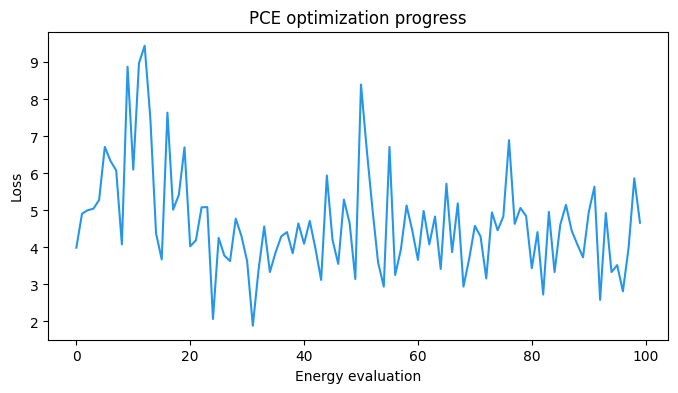

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(cost_history, color="#2696EB")
plt.xlabel("Energy evaluation")
plt.ylabel("Loss")
plt.title("PCE optimization progress")
plt.show()

## Decode the Optimized Expectations

The final expectations are sign-rounded in their original variable order.
`DecodedSamples` reports both the immutable assignment and its exact Ising
energy, which equals minus the cut value for this model.

In [9]:
final_estimates = measure_expectations(optimization.x, shots=FINAL_SHOTS_PER_OBSERVABLE)
final_expectations = tuple(estimate.value for estimate in final_estimates)
assert all(estimate.shots == FINAL_SHOTS_PER_OBSERVABLE for estimate in final_estimates)
decoded = encoding.decode(final_expectations)
solution = decoded.lowest
spins = solution.values
pce_cut = sum(spins[left] != spins[right] for left, right in EDGES)

print("Final per-variable expectations:")
for index, estimate in enumerate(final_estimates):
    print(f"  <P_{index:2d}> = {estimate.value:+.4f} ± {estimate.standard_error:.4f}")
print("Decoded spins:", dict(spins))
print(f"Decoded energy: {solution.energy:+.1f}")
print(f"PCE cut: {pce_cut}")

assert model.energy(spins) == solution.energy
assert np.isclose(pce_cut, -solution.energy, rtol=0.0, atol=1e-12)

Final per-variable expectations:
  <P_ 0> = -0.0557 ± 0.0221
  <P_ 1> = +0.2959 ± 0.0211
  <P_ 2> = +0.9248 ± 0.0084
  <P_ 3> = +0.2305 ± 0.0215
  <P_ 4> = +0.0312 ± 0.0221
  <P_ 5> = +0.0273 ± 0.0221
  <P_ 6> = +0.0420 ± 0.0221
  <P_ 7> = -0.2969 ± 0.0211
  <P_ 8> = -0.0566 ± 0.0221
  <P_ 9> = +0.9238 ± 0.0085
  <P_10> = -0.1797 ± 0.0217
  <P_11> = -0.0527 ± 0.0221
  <P_12> = +0.0273 ± 0.0221
  <P_13> = +0.0830 ± 0.0220
  <P_14> = -0.0947 ± 0.0220
  <P_15> = -0.1689 ± 0.0218
  <P_16> = -0.1113 ± 0.0220
  <P_17> = -0.0859 ± 0.0220
  <P_18> = -0.0869 ± 0.0220
  <P_19> = -0.0977 ± 0.0220
Decoded spins: {0: -1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: -1, 8: -1, 9: 1, 10: -1, 11: -1, 12: 1, 13: 1, 14: -1, 15: -1, 16: -1, 17: -1, 18: -1, 19: -1}
Decoded energy: -19.0
PCE cut: 19


(pce-classical-baseline)=
### Classical Baseline (Brute Force)

Enumerating all $2^{20} = 1{,}048{,}576$ spin configurations means
checking about one million assignments. That is too many for a
simple Python loop, but a single vectorized NumPy pass finishes in a
fraction of a second.
We label each configuration by an integer whose bit $i$ encodes
$s_i = +1$ (bit $0$) or $s_i = -1$ (bit $1$), then count edges with
$s_i \neq s_j$. This gives us the ground-truth optimum to compare
the PCE result against in the next subsection.

In [10]:
assignments = np.arange(2**NUM_NODES, dtype=np.int64)
cuts = np.zeros(2**NUM_NODES, dtype=np.int32)
for left, right in EDGES:
    left_spins = 1 - 2 * ((assignments >> left) & 1)
    right_spins = 1 - 2 * ((assignments >> right) & 1)
    cuts += (left_spins != right_spins).astype(np.int32)

best_cut = int(cuts.max())
optimal_assignments = np.flatnonzero(cuts == best_cut)
approximation_ratio = pce_cut / best_cut

print(f"Brute-force optimum: {best_cut}")
print(f"Number of optimal partitions: {len(optimal_assignments)}")
print(f"PCE approximation ratio: {approximation_ratio:.3f}")

assert best_cut == 26
assert 0.0 <= approximation_ratio <= 1.0

Brute-force optimum: 26
Number of optimal partitions: 12
PCE approximation ratio: 0.731


#### Visualize the Best Solution

Color each node by its side of the partition. Nodes with different
colors sit on opposite sides of the cut.

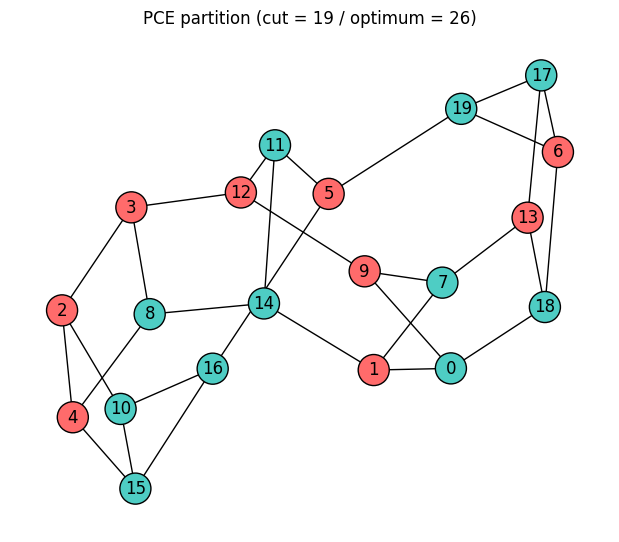

In [11]:
colors = ["#FF6B6B" if spins[index] == 1 else "#4ECDC4" for index in graph]
plt.figure(figsize=(6, 5))
nx.draw(
    graph,
    positions,
    with_labels=True,
    node_color=colors,
    node_size=500,
    edgecolors="black",
)
plt.title(f"PCE partition (cut = {pce_cut} / optimum = {best_cut})")
plt.show()

## Summary

In this tutorial we encoded a 20-node 3-regular MaxCut problem with
Pauli Correlation Encoding (PCE) and ran the full Qamomile workflow,
from building the correlator encoding through to decoding the optimized
expectation values into a spin assignment.

- **Qubit resource efficiency:** PCE represented the 20 spin variables with
  only 3 qubits through 2-body Pauli correlators, roughly a 7x reduction
  over the one-qubit-per-variable QAOA encoding.
- **Surrogate-loss training:** the variational loop minimized the
  tanh-relaxed surrogate rather than an energy directly, and the
  decoded assignment is compared with the brute-force optimum; finite-shot
  training does not guarantee an optimal partition.
- **End-to-end Qamomile path:** `PauliCorrelationEncoding` encoded the given
  classical variables and exposed the corresponding observables through
  `encoding.observables`; a hardware-efficient `@qkernel` ansatz and
  Qamomile estimators measured each correlator with an explicit shot budget,
  the optimizer tuned the parameters, and `encoding.decode` sign-rounded
  the expectations obtained with
  those tuned parameters back into the corresponding classical variables.

This `PauliCorrelationEncoding` workflow applies to any QUBO / Ising
combinatorial problem where qubit count is the bottleneck: swap in your
own `BinaryModel` and reuse the encode, estimate, and decode steps
shown above.